# k-nearest-neighbour donor basins

**Question.** How well can we predict daily flow at an "ungauged" basin by borrowing the observed flow of the *k* most similar gauged basins?

This is the classic regionalisation baseline (Oudin et al., 2008) and the kNN comparison suggested in the midway feedback. It has **nothing to train**: for each test basin we pick donors, then average their flow day by day:

$$\hat q_i(t) = \sum_{j \in \text{kNN}(i)} w_j\, q_j(t), \qquad w_j \propto 1/d_{ij} \;\text{(or equal weights)}$$

Streamflow is in mm/day (already divided by catchment area), so donors of different sizes can be averaged directly.

**What "similar" means** is the experiment. This notebook starts with three distance spaces:

| Variant | Distance between basins | Tests |
| --- | --- | --- |
| `spatial` | great-circle km between gauges | spatial proximity (k = 1 is the nearest-gauge baseline) |
| `attr_curated` | Euclidean on ~13 standardised attributes | physical similarity, hand-picked drivers |
| `attr_pca` | Euclidean on the top PCA components of all 179 numeric attributes | physical similarity, data-driven |

**Rules inherited from notebook 01** (`data/processed/splits/`):
- Donors come only from the fold's `train` basins; `buffer` basins are never donors. So spatial donors are always ≥ 100 km from the test basin.
- Scalers and PCA are fit on the fold's train basins only.
- Donors come from the **same region** (a US basin never borrows Australian flow; their seasons are opposite).
- Scores use the **test period** (2004-10 to 2014-09) at each test basin.

**One caveat to state in the report.** Donor transfer uses the donors' observed flow *during the test years*. That's realistic (nearby gauges are running today), but it's information the LightGBM models won't get. See the "next steps" at the end.

**How to use this notebook.** It's laid out as steps. Run them in order the first time; after that, the cells in steps 4–6 are the ones to experiment with.

## Step 1. Setup and inputs

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import haversine_distances
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = REPO / "data" / "processed"
SPLITS = PROCESSED / "splits"
DAILY = REPO / "data" / "features"
RESULTS = REPO / "data" / "results"
EARTH_RADIUS_KM = 6371.0

cfg = json.loads((SPLITS / "config.json").read_text())
basins = pd.read_csv(SPLITS / "basins.csv", index_col="gauge_id")
roles = pd.read_csv(SPLITS / "fold_roles.csv")
static = pd.read_parquet(PROCESSED / "features" / "static_attributes.parquet")
groups = json.loads((PROCESSED / "features" / "feature_groups.json").read_text())

for p in [DAILY / f"daily_{s}.parquet" for s in cfg["subsets"]]:
    assert p.exists(), f"{p} not found: run notebooks/01_preprocessing.ipynb first"

N_FOLDS = cfg["n_folds"]
LOG_EPS = cfg["log_eps"]
print("folds:", N_FOLDS, "| test period:", cfg["periods"]["test"], "| basins:", len(basins))
roles.pivot_table(index="fold", columns="role", values="gauge_id", aggfunc="count")

folds: 5 | test period: ['2004-10-01', '2014-09-30'] | basins: 1208


role,buffer,test,train
fold,,,
0,100,241,867
1,61,242,905
2,106,242,860
3,77,242,889
4,92,241,875


### Observed flow, as one wide table

Donor averaging is just matrix arithmetic if flow is a table with one row per day and one column per basin. Load the test period for every basin (each basin is a test basin in one fold and a potential donor in the other four).

In [2]:
test_start, test_end = map(pd.Timestamp, cfg["periods"]["test"])
frames = []
for subset in cfg["subsets"]:
    d = pd.read_parquet(DAILY / f"daily_{subset}.parquet", columns=["gauge_id", "date", "streamflow"],
                        filters=[("period", "==", "test")])
    d["gauge_id"] = d["gauge_id"].astype(str)
    frames.append(d)
Q = (pd.concat(frames).pivot(index="date", columns="gauge_id", values="streamflow")
     .reindex(columns=basins.index).astype("float64"))
print(Q.shape, f"| {Q.index.min().date()} to {Q.index.max().date()} | missing: {Q.isna().mean().mean():.1%}")
Q.iloc[:3, :4]

(3652, 1208) | 2004-10-01 to 2014-09-30 | missing: 1.2%


gauge_id,camels_01013500,camels_01022500,camels_01030500,camels_01031500
date,,,,
2004-10-01,0.93,0.4,0.24,0.24
2004-10-02,0.89,0.4,0.23,0.24
2004-10-03,0.84,0.4,0.22,0.22


## Step 2. Scoring functions

Each test basin gets one score per metric, comparing predicted and observed flow over the test days where both exist:

- **NSE**: $1 - \sum (q_{obs} - \hat q)^2 / \sum (q_{obs} - \bar q_{obs})^2$. 1 is perfect; 0 means "no better than that basin's own mean flow"; negative is worse.
- **KGE** (Gupta et al., 2009): $1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}$, combining timing ($r$, correlation), variability ($\alpha$, ratio of standard deviations) and volume ($\beta$, ratio of means). The parts are kept too, because they say *why* a prediction is off.
- **log-NSE**: NSE on $\log(q + \varepsilon)$, which weights low flows (drought) rather than floods.

In [3]:
def _paired(obs, sim):
    m = np.isfinite(obs) & np.isfinite(sim)
    return obs[m], sim[m]


def nse(obs, sim):
    o, s = _paired(np.asarray(obs, float), np.asarray(sim, float))
    denom = np.sum((o - o.mean()) ** 2)
    return np.nan if len(o) < 2 or denom == 0 else 1 - np.sum((o - s) ** 2) / denom


def kge_parts(obs, sim):
    o, s = _paired(np.asarray(obs, float), np.asarray(sim, float))
    if len(o) < 2 or o.std() == 0 or o.mean() == 0:
        return dict(kge=np.nan, r=np.nan, alpha=np.nan, beta=np.nan)
    r = np.corrcoef(o, s)[0, 1] if s.std() > 0 else 0.0
    alpha, beta = s.std() / o.std(), s.mean() / o.mean()
    return dict(kge=1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2), r=r, alpha=alpha, beta=beta)


def score(obs, sim):
    lo, ls = np.log(np.asarray(obs, float) + LOG_EPS), np.log(np.clip(np.asarray(sim, float), 0, None) + LOG_EPS)
    return dict(nse=nse(obs, sim), log_nse=nse(lo, ls), **kge_parts(obs, sim))


# Quick checks: a perfect prediction, the observed mean, and a prediction that is 20% too high
o = Q.iloc[:, 0].to_numpy()
pd.DataFrame({
    "perfect": score(o, o),
    "obs mean every day": score(o, np.full_like(o, np.nanmean(o))),
    "20% too high": score(o, 1.2 * o),
}).T.round(3)

,nse,log_nse,kge,r,alpha,beta
perfect,1.000,1.000,1.000,1.0,1.0,1.0
obs mean every day,0.000,-0.218,-0.414,-0.0,0.0,1.0
20% too high,0.926,0.959,0.717,1.0,1.2,1.2


## Step 3. Distance spaces

Each function takes the fold's train and test basins and returns a **test × train distance matrix**. Anything fitted (scaler, PCA) is fit on the train basins only, then applied to the test basins.

**Curated features.** One or two per hydrological driver, chosen so no driver is counted many times over (the monthly HydroATLAS columns would otherwise dominate the distance). Edit `CURATED` to try other sets.

| Driver | Features |
| --- | --- |
| Water supply and demand | `p_mean_train`, `aridity_train` |
| Snow | `frac_snow_train` |
| Rainfall regime | `high_prec_freq_train`, `low_prec_freq_train` |
| Size and terrain | `log_area`, `ele_mt_sav` (elevation), `slp_dg_sav` (slope) |
| Land cover | `for_pc_sse` (forest) |
| Soils and geology | `cly_pc_sav` (clay), `snd_pc_sav` (sand), `kar_pc_sse` (karst), `gwt_cm_sav` (groundwater depth) |

In [4]:
CURATED = [
    "p_mean_train", "aridity_train", "frac_snow_train", "high_prec_freq_train", "low_prec_freq_train",
    "log_area", "ele_mt_sav", "slp_dg_sav", "for_pc_sse",
    "cly_pc_sav", "snd_pc_sav", "kar_pc_sse", "gwt_cm_sav",
]
PCA_FEATURES = groups["numeric"]   # all 179 numeric static features
N_PCA = 10


def dist_spatial(train_ids, test_ids):
    a = np.radians(basins.loc[test_ids, ["lat", "lon"]].to_numpy())
    b = np.radians(basins.loc[train_ids, ["lat", "lon"]].to_numpy())
    return haversine_distances(a, b) * EARTH_RADIUS_KM


def _euclid(A, B):
    return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))


def dist_attr_curated(train_ids, test_ids):
    scaler = StandardScaler().fit(static.loc[train_ids, CURATED])
    return _euclid(scaler.transform(static.loc[test_ids, CURATED]), scaler.transform(static.loc[train_ids, CURATED]))


def dist_attr_pca(train_ids, test_ids):
    scaler = StandardScaler().fit(static.loc[train_ids, PCA_FEATURES])
    pca = PCA(n_components=N_PCA, random_state=0).fit(scaler.transform(static.loc[train_ids, PCA_FEATURES]))
    z = lambda ids: pca.transform(scaler.transform(static.loc[ids, PCA_FEATURES]))
    return _euclid(z(test_ids), z(train_ids))


DISTANCES = {"spatial": dist_spatial, "attr_curated": dist_attr_curated, "attr_pca": dist_attr_pca}

## Step 4. Donors and predictions for one fold

`fold_ids` returns the fold's train and test basins (only basins with enough valid flow in that period, per notebook 01). `donor_weights` turns a distance matrix into a weight matrix with *k* non-zero entries per row, restricted to the same region.

Prediction is then one matrix product. When a donor is missing a day, the weights are renormalised over the donors that do have it.

In [5]:
def fold_ids(k):
    r = roles[roles["fold"] == k].set_index("gauge_id")
    train = r.index[(r["role"] == "train") & basins.loc[r.index, "usable_train"]]
    test = r.index[(r["role"] == "test") & basins.loc[r.index, "usable_test"]]
    return list(train), list(test)


def donor_weights(D, train_ids, test_ids, k, weighting="inverse"):
    # (test x train) weights: k nearest same-region donors per test basin, rows sum to 1
    same_region = (basins.loc[test_ids, "region"].to_numpy()[:, None]
                   == basins.loc[train_ids, "region"].to_numpy()[None, :])
    D = np.where(same_region, D, np.inf)
    nearest = np.argsort(D, axis=1)[:, :k]
    W = np.zeros_like(D)
    rows = np.arange(len(test_ids))[:, None]
    if weighting == "inverse":
        W[rows, nearest] = 1 / np.maximum(D[rows, nearest], 1e-6)
    else:
        W[rows, nearest] = 1.0
    return W / W.sum(axis=1, keepdims=True)


def predict(W, train_ids, test_ids):
    # weighted daily average of donor flow, renormalised over donors with data that day
    q = Q[train_ids].to_numpy()
    have = np.isfinite(q)
    num = np.nan_to_num(q) @ W.T
    den = have.astype(float) @ W.T
    with np.errstate(invalid="ignore", divide="ignore"):  # days where no donor has data -> NaN
        return pd.DataFrame(np.where(den > 0, num / den, np.nan), index=Q.index, columns=test_ids)


FOLD, K, METRIC = 0, 5, "attr_curated"
train_ids, test_ids = fold_ids(FOLD)
D = DISTANCES[METRIC](train_ids, test_ids)
W = donor_weights(D, train_ids, test_ids, K)
pred = predict(W, train_ids, test_ids)
print(f"fold {FOLD}: {len(train_ids)} train / {len(test_ids)} test basins | {METRIC}, k={K}")
pred.iloc[:3, :4]

fold 0: 867 train / 241 test basins | attr_curated, k=5


,camels_01022500,camels_01030500,camels_01031500,camels_01047000
date,,,,
2004-10-01,0.461132,0.596682,0.472851,0.571658
2004-10-02,0.529171,0.651383,0.506984,0.609118
2004-10-03,0.527267,0.647693,0.501303,0.600210


### Look at one test basin

Before scoring everything, check that the mechanics make sense: who the donors are, how far away they are, and how the borrowed hydrograph compares with the observed one. Change `EXAMPLE` to explore other basins.

camels_01022500 - Narraguagus River at Cherryfield, Maine


,donor,weight,distance,km_away,name
3,camels_04122200,0.245,1.009,1465.0,"WHITE RIVER NEAR WHITEHALL, MI"
4,camels_04122500,0.215,1.151,1459.0,"PERE MARQUETTE RIVER AT SCOTTVILLE, MI"
2,camels_04074950,0.183,1.353,1635.0,"WOLF RIVER AT LANGLADE, WI"
0,camels_01078000,0.179,1.382,326.0,"SMITH RIVER NEAR BRISTOL, NH"
1,camels_04063700,0.177,1.398,1609.0,"POPPLE RIVER NEAR FENCE, WI"


nse       -0.033
log_nse    0.105
kge       -0.039
r          0.571
alpha      0.245
beta       0.428
dtype: float64

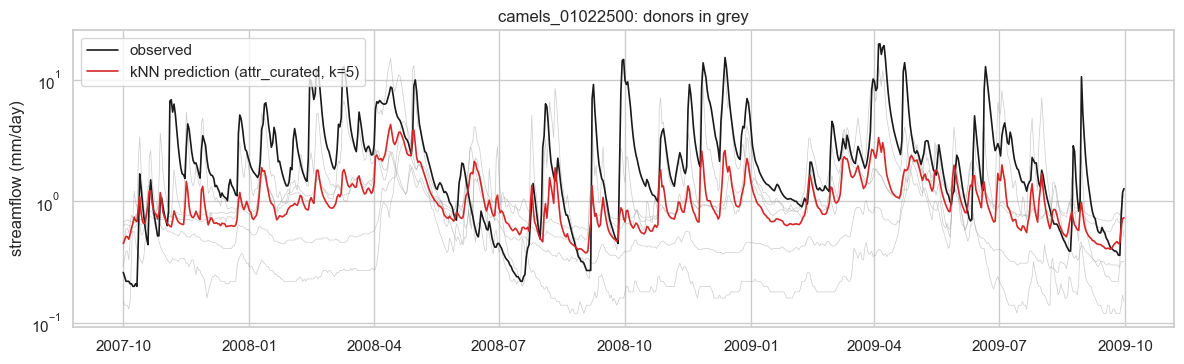

In [6]:
EXAMPLE = test_ids[0]
i = test_ids.index(EXAMPLE)
donors = pd.DataFrame({
    "donor": np.array(train_ids)[W[i] > 0],
    "weight": W[i][W[i] > 0],
    "distance": D[i][W[i] > 0],
}).sort_values("weight", ascending=False)
donors["km_away"] = dist_spatial(donors["donor"].tolist(), [EXAMPLE])[0].round(0)
donors["name"] = basins.loc[donors["donor"], "gauge_name"].to_numpy()
print(EXAMPLE, "-", basins.loc[EXAMPLE, "gauge_name"])
display(donors.round(3))

window = slice("2007-10-01", "2009-09-30")
fig, ax = plt.subplots(figsize=(12, 3.8))
for d in donors["donor"]:
    ax.plot(Q.loc[window, d], lw=0.5, alpha=0.5, color="0.6")
ax.plot(Q.loc[window, EXAMPLE], color="k", lw=1.2, label="observed")
ax.plot(pred.loc[window, EXAMPLE], color="tab:red", lw=1.2, label=f"kNN prediction ({METRIC}, k={K})")
ax.set(yscale="log", ylabel="streamflow (mm/day)", title=f"{EXAMPLE}: donors in grey")
ax.legend()
plt.tight_layout()
pd.Series(score(Q[EXAMPLE], pred[EXAMPLE])).round(3)

## Step 5. Score every fold, metric and k

Loop over folds × distance spaces × k × weighting, and keep one row per (test basin, setting). Over the 5 folds every basin is scored exactly once per setting.

This takes well under a minute: there is nothing to train, only distances and matrix products.

In [7]:
KS = [1, 3, 5, 10, 20]
WEIGHTINGS = ["inverse", "uniform"]

rows = []
for fold in range(N_FOLDS):
    train_ids, test_ids = fold_ids(fold)
    for metric, dist_fn in DISTANCES.items():
        D = dist_fn(train_ids, test_ids)
        for weighting in WEIGHTINGS:
            for k in KS:
                pred = predict(donor_weights(D, train_ids, test_ids, k, weighting), train_ids, test_ids)
                for g in test_ids:
                    rows.append({"fold": fold, "gauge_id": g, "region": basins.at[g, "region"],
                                 "metric": metric, "weighting": weighting, "k": k,
                                 **score(Q[g].to_numpy(), pred[g].to_numpy())})
scores = pd.DataFrame(rows)
RESULTS.mkdir(parents=True, exist_ok=True)
scores.to_csv(RESULTS / "knn_donor_scores.csv", index=False)
print(scores.shape, "->", (RESULTS / "knn_donor_scores.csv").relative_to(REPO))
scores.head()

(36240, 12) -> data\results\knn_donor_scores.csv


,fold,gauge_id,region,metric,weighting,k,nse,log_nse,kge,r,alpha,beta
0,0,camels_01022500,US,spatial,inverse,1,-0.263176,0.063589,0.429648,0.505799,1.204908,0.802314
1,0,camels_01030500,US,spatial,inverse,1,0.426977,0.552558,0.612002,0.680780,0.827993,0.861962
2,0,camels_01031500,US,spatial,inverse,1,0.181243,0.405234,0.286250,0.459953,0.576606,0.803722
3,0,camels_01047000,US,spatial,inverse,1,0.452698,0.598559,0.534437,0.691447,0.729999,0.779447
4,0,camels_01052500,US,spatial,inverse,1,0.442687,0.565430,0.409433,0.698211,0.528319,0.812358


## Step 6. Summarise

Median across basins (not mean: a few arid basins have very negative NSE). Treat this table as an **ablation**: how skill changes with the distance space, k and weighting. Picking the best row here would be tuning on the test basins; see "next steps" for the clean way to choose k.

In [8]:
summary = (scores.groupby(["metric", "weighting", "k"])[["nse", "kge", "log_nse"]].median()
           .unstack("k").round(3))
summary["nse"]

k                          1      3      5      10     20
metric       weighting                                   
attr_curated inverse   -0.435 -0.254 -0.193 -0.154 -0.116
             uniform   -0.435 -0.249 -0.192 -0.173 -0.126
attr_pca     inverse   -0.259 -0.082 -0.032  0.014  0.044
             uniform   -0.259 -0.085 -0.041  0.008  0.026
spatial      inverse   -0.139 -0.018  0.017  0.034  0.058
             uniform   -0.139 -0.014  0.011  0.023  0.026

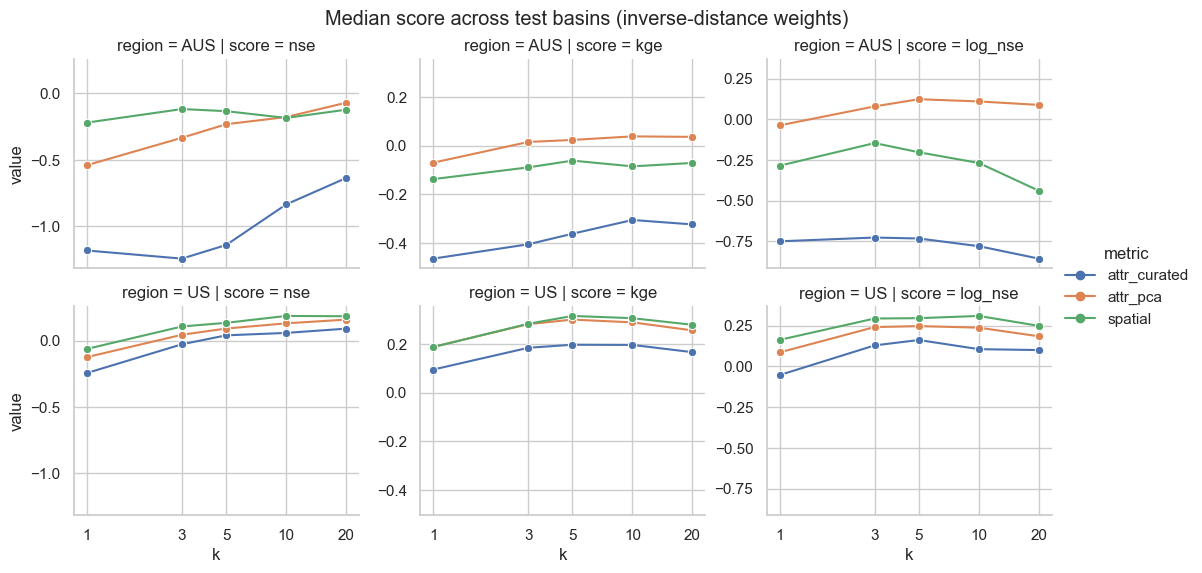

In [9]:
by_region = (scores.query("weighting == 'inverse'")
             .groupby(["region", "metric", "k"])[["nse", "kge", "log_nse"]].median().reset_index())
g = sns.relplot(data=by_region.melt(id_vars=["region", "metric", "k"], var_name="score"),
                x="k", y="value", hue="metric", col="score", row="region", kind="line", marker="o",
                height=2.8, aspect=1.3, facet_kws={"sharey": "col"})
g.set(xscale="log", xticks=KS, xticklabels=KS)
g.figure.suptitle("Median score across test basins (inverse-distance weights)", y=1.02)
plt.show()

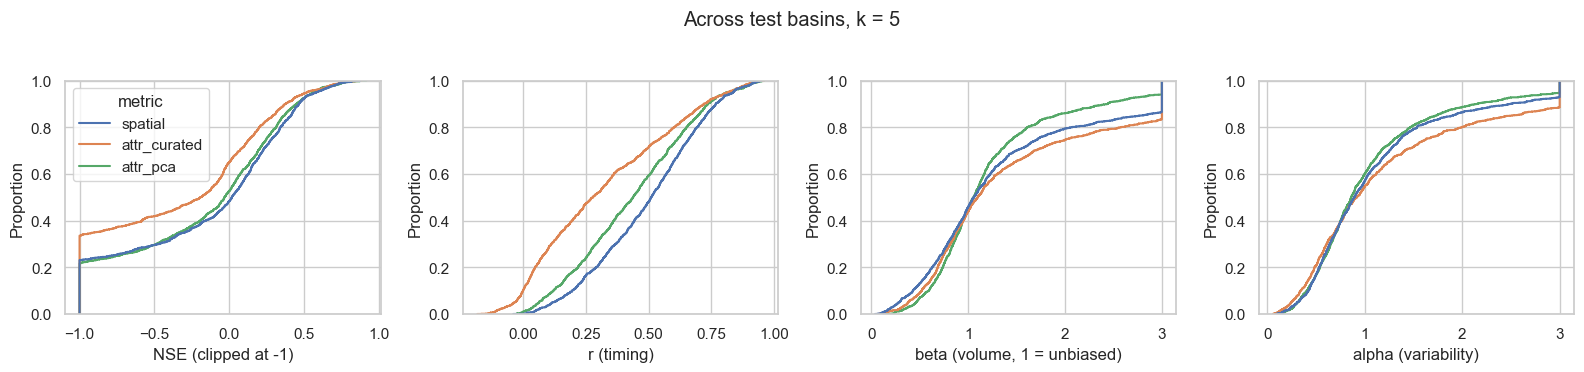

In [10]:
# Distribution across basins for one setting per metric, with the KGE parts that explain it
K_SHOW = 5
sub = scores.query("weighting == 'inverse' and k == @K_SHOW")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
sns.ecdfplot(data=sub, x=sub["nse"].clip(-1, 1), hue="metric", ax=axes[0]); axes[0].set(xlabel="NSE (clipped at -1)")
sns.ecdfplot(data=sub, x="r", hue="metric", ax=axes[1], legend=False); axes[1].set(xlabel="r (timing)")
sns.ecdfplot(data=sub, x=sub["beta"].clip(0, 3), hue="metric", ax=axes[2], legend=False); axes[2].set(xlabel="beta (volume, 1 = unbiased)")
sns.ecdfplot(data=sub, x=sub["alpha"].clip(0, 3), hue="metric", ax=axes[3], legend=False); axes[3].set(xlabel="alpha (variability)")
fig.suptitle(f"Across test basins, k = {K_SHOW}", y=1.03)
plt.tight_layout()

## Step 7. How much does the split design matter?

The scores above are low, and that is largely the split design doing its job. To show it, rerun the spatial donors (k = 1 and 5) under three designs:

- **blocks + buffer**: the notebook-01 design used above
- **blocks, no buffer**: `buffer` basins allowed as donors, so the nearest donor can sit just across a block edge
- **random basin folds**: no spatial structure at all, so a test basin's near-twin is usually a donor

If random folds score much higher, much of what looks like "skill" in a random-fold evaluation is really copying a nearby gauge, which a truly remote ungauged site would not have (Roberts et al., 2017). This comparison is worth a figure in the report.

In [11]:
def ids_no_buffer(fold):
    r = roles[roles["fold"] == fold].set_index("gauge_id")
    return list(r.index[r["role"] != "test"]), list(r.index[r["role"] == "test"])


rng = np.random.default_rng(cfg["seed"])
random_fold = pd.Series(rng.permutation(np.arange(len(basins)) % N_FOLDS), index=basins.index)


def ids_random(fold):
    return list(random_fold.index[random_fold != fold]), list(random_fold.index[random_fold == fold])


design_rows = []
for design, ids_fn in {"blocks + buffer": fold_ids, "blocks, no buffer": ids_no_buffer, "random basin folds": ids_random}.items():
    for fold in range(N_FOLDS):
        train_ids, test_ids = ids_fn(fold)
        D = dist_spatial(train_ids, test_ids)
        for k in [1, 5]:
            pred = predict(donor_weights(D, train_ids, test_ids, k), train_ids, test_ids)
            for j, g in enumerate(test_ids):
                design_rows.append({"design": design, "k": k, "gauge_id": g, "region": basins.at[g, "region"],
                                    "nearest_donor_km": D[j].min(), **score(Q[g].to_numpy(), pred[g].to_numpy())})
designs = pd.DataFrame(design_rows)
designs.groupby(["design", "k"])[["nearest_donor_km", "nse", "kge", "log_nse"]].median().round(3)

nearest_donor_km    nse    kge  log_nse
design             k                                         
blocks + buffer    1           161.849 -0.139  0.021   -0.020
                   5           161.849  0.017  0.147    0.120
blocks, no buffer  1           126.151  0.041  0.136    0.127
                   5           126.151  0.146  0.202    0.287
random basin folds 1            29.373  0.443  0.470    0.602
                   5            29.373  0.541  0.515    0.620

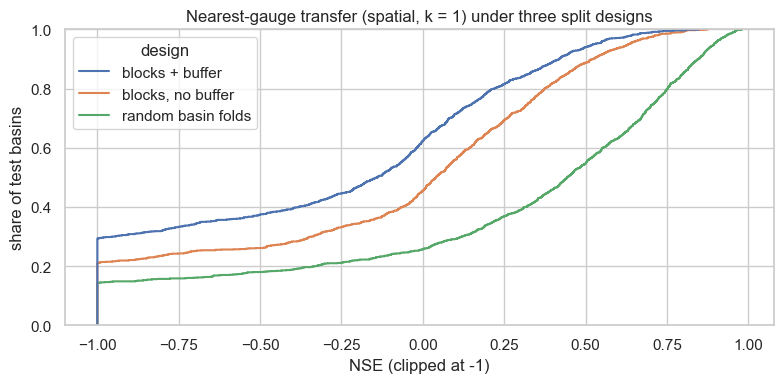

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(data=designs.query("k == 1"), x=designs.query("k == 1")["nse"].clip(-1, 1), hue="design", ax=ax)
ax.set(xlabel="NSE (clipped at -1)", ylabel="share of test basins",
       title="Nearest-gauge transfer (spatial, k = 1) under three split designs")
plt.tight_layout()

## Next steps

Roughly in the order I'd tackle them:

1. **Choose k and the distance space without touching the test basins.** Within each fold, treat each *block* of train basins as ungauged in turn and predict it from the other train basins over the **train** years (leave-one-block-out; the `block` column in `basins.csv`). Pick the setting with the best median NSE, then score only that setting on the fold's test basins. This is the number that goes in the results table.
2. **k-means donors.** Same transfer rule, different grouping: donors are all train basins in the test basin's k-means cluster (fit on the fold's train basins). This is the kNN vs k-means comparison from the feedback.
3. **Combined distance.** $d = \alpha\, d_{attr} + (1-\alpha)\, d_{space}$, each rescaled to [0, 1] (Oudin et al., 2008 suggest the combination helps).
4. **Paired comparisons with uncertainty.** Per basin, the difference between two variants, the share of basins where one wins, and a bootstrap confidence interval on the median.
5. **Fewer training basins** (25/50/100/all): subsample each fold's train basins and rerun; donors get farther away and skill should drop (Gauch et al., 2021).
6. **A fair input for LightGBM.** A neighbour feature that uses only training data, such as the kNN donors' mean training-period flow, so the model-based arms can use neighbour information without seeing test-year flow.